---
title: "Steam methane reformer tube (Xu and Froment, 1989)"
description: "Is the conversion of an industrial reformer tube limited by the heat flux? Part II's own model, rebuilt and probed."
categories: [sec:D, struct:S2, struct:S3, struct:S8, tier:T1, data:tier4]
date: 2026-11-28
---

# Steam methane reformer tube: is it limited by the heat flux?

**Catalog ID:** `D3.1` · **Structures:** `S2`, `S3`, `S8` · **Tier:** T1

Xu and Froment (1989, Part II) put their Part I kinetics into a slab model of the
catalyst ring and the slab into a one-dimensional heterogeneous model of an industrial
reformer tube, and state (p. 101) that the conversion "is limited mainly by the heat flux
supplied per unit weight of catalyst". This page rebuilds that model with pymrm and
tests the statement inside it: how much does the exit conversion respond to the
catalyst activity, and how much to the heat? It also audits the printed inputs and
compares the pellet and the tube with the paper's figures.

**What the comparison is.** Part II prints no plant measurement. Every comparison on
this page is with the authors' own simulation (Figs. 3 to 7), digitised: a
reproduction test of a model, not a validation against data.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "D3.1-xu-froment-reformer-tube"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import importlib.util
import math
import multiprocessing as mp
import time
from concurrent.futures import ProcessPoolExecutor
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from scipy.interpolate import CubicSpline
from pymrm.checks import find_roots, observed_orders

from gallery_utils import Claims, assert_check_values, load_data, load_meta
import model as M

claims = Claims(PAGE.split("-")[0])
T_START = time.time()


def page_module(page):
    """Import another page's model.py: from the checkout, else from GitHub at GALLERY_REF."""
    src = next((p / "pages" / page / "model.py" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "pages" / page / "model.py").is_file()), None)
    if src is None:
        src = _shared / f"{page}-model.py"
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/computational-chemical-engineering/"
            f"pymrm-gallery/{GALLERY_REF}/pages/{page}/model.py", src)
    name = page.split("-")[0].replace(".", "_") + "_model"
    spec = importlib.util.spec_from_file_location(name, src)
    mod = importlib.util.module_from_spec(spec)
    sys.modules[name] = mod            # dataclasses look their module up while defining
    spec.loader.exec_module(mod)
    return mod


def say(text):
    display(Markdown(text))


def show(frame, uuid, digits=None):
    """Display a table with a pinned id, so two runs print the same HTML."""
    sty = frame.style.hide(axis="index")
    if digits:
        num = [c for c in frame.columns if pd.api.types.is_numeric_dtype(frame[c])]
        sty = sty.format({c: "{:." + digits + "}" for c in num})
    display(HTML(sty.set_uuid(uuid).to_html()))

## Background

A steam reformer tube is a long, narrow packed bed (here 10.16 cm inside, 12 m long)
hung in a furnace. The catalyst converts CH4 + H2O ⇌ CO + 3 H2 (I, strongly
endothermic), CO + H2O ⇌ CO2 + H2 (II) and CH4 + 2 H2O ⇌ CO2 + 4 H2 (III), and the
heat for I and III comes through the tube wall. Two things can limit the exit
conversion: the catalyst (activity and pore diffusion) or the heat that reaches the gas.
Part II's industrial simulation found effectiveness factors near 0.02, so only a thin
outer shell of each ring works, and concluded that the heat flux is the limit. A
statement of that kind is a statement about a sensitivity, so this page measures the
two sensitivities in a rebuild of the authors' model.

Not repeated: the model ladder (page `D1.1`) and the Thiele closed forms (page `B1.1`).

In [3]:
ST_ = load_data("xu-froment-1989-ii-statements.csv", page=PAGE, dtype=str)
say("\n".join(f"- **{r.id}** (p. {r.journal_page}): \"{r.quote}\"" for r in ST_.itertuples()))

- **S1** (p. 101): "The conversion in a steam reformer is limited mainly by the heat flux supplied per unit weight of catalyst."
- **S2** (p. 101): "For reactions I and III, the approach to equilibrium exceeds 70% in the second half of the reactor. It only slowly increases to 80%"
- **S3** (p. 101): "Beyond 3 m already, reaction II ... comes very close to equilibrium."
- **S4** (p. 101): "Its value is about 10°C at the end of the heated part of the tube."
- **S5** (p. 101): "The effectiveness factor of reaction II shows a discontinuity at a reactor length of 3.4 m"
- **S6** (p. 101): "The effectiveness factors of reactions I and III both decrease through the reactor"
- **S7** (p. 101): "These low effectiveness factors also explain why many authors obtained activation energies for steam reforming of approximately half the intrinsic values."
- **S8** (p. 100): "Since the partial pressure gradients are limited to a very thin layer near the surface, planar geometry was used."
- **S9** (p. 100): "The two splines, in which the concentration gradients occur, have a total thickness of 0.08 mm."
- **S10** (p. 100): "easily calculated to be 1.071 times that of the active part of the ring"
- **S11** (p. 100): "The intrinsic rate r2 changes from positive to negative at a reactor length of about 4 m."
- **S12** (p. 101): "The partial pressures of the catalyst surface components are very close to the equilibrium values at reactor lengths exceeding 6 m."

## The published model

Species CH4, H2O, H2, CO, CO2, N2; x is the total CH4 conversion and y the
conversion into CO2, so every composition is the feed plus a stoichiometric change
and C, H and O balance exactly.

**Pellet (eqs. 13, 6e-g, 7, 9).** One active layer of half width l = 2 mm is treated
as a slab, x = 0 at the surface, no flux at x = l. With effective diffusivities
D_e,i, constant across the pellet,

$$ D_{e,CH_4}\,\frac{d^2 p_{CH_4}}{dx^2} = R T \rho_s\, r_{CH_4}(p), \qquad
   D_{e,CO_2}\,\frac{d^2 p_{CO_2}}{dx^2} = -R T \rho_s\, r_{CO_2}(p), $$

with r_CH4 = r1 + r3 and r_CO2 = r2 + r3 (Part I's eq. 3 rates), p = p_bulk at
x = 0. The other three partial pressures follow from the element balances (eqs. 6e-g).
The observed rate is the layer average, r_obs = (1/l) ∫ r dx; the paper divides the
slab value by 1.071 for the ring (p. 100), and eta_j = r_j,obs / r_j(bulk). Eq. 13b is printed
with the sign of 13a (p. 100); r_CO2 is a formation rate, so the sign is corrected here.

**Tube (eqs. 10a-c).** Plug flow with

$$ \frac{dx}{dz} = \frac{\Omega \rho_B\, r_{CH_4,obs}}{F_{CH_4}^0}, \quad
   \frac{dy}{dz} = \frac{\Omega \rho_B\, r_{CO_2,obs}}{F_{CH_4}^0}, \quad
   \frac{d}{dz}\sum_i F_i h_i(T) = \pi d_{ti}\, q(z), $$

Ω = π d_ti²/4, ρ_B = ρ_s (1 - ε_B). The energy balance is written for the
enthalpy flow, which is equivalent to eq. 10c and makes the energy budget exact for
the discrete march. The heat input q is either an imposed flux q(z) or
q = U (T_w(z) - T) (the eq. 10c form with T_r = T_w). Part II computes T_w from a
furnace model it does not print.

**Effective diffusivity (eqs. 1-5).** For each pore class i,
1/D_A(r_i) = 1/D_mA + 1/D_KA(r_i), averaged with the pore-volume fractions of Table 1,
times ε_s/τ with τ = 3.54 (fitted in Part II). D_mA is Wilke's mixture rule over
Fuller binaries at the bulk state, D_K = (d_i/3) (8RT/(πM))^(1/2).

## Parameters and assumptions

Kinetics: Part I's Table 6 through page `C2.1` (its parameter CSV and its
`XuFroment` class, at Part I's reference activity a = 1, with C2.1's equilibrium
correlation; neither the activity of the Part II simulation nor its equilibrium
constants are printed). Enthalpies: NIST Shomate rows of page `C2.5` for H2O, H2, CO,
CO2, N2 and a NIST CH4 row (this page's data). Fuller diffusion volumes and atomic
weights: page `A4.5`. Table 2 (feed, tube, ring) and Table 1 (pores): this page's data.

Page choices, each named as a choice and swept where it matters:

| id | choice | alternative swept |
|---|---|---|
| A1 | activity a = 1 | 0.5, 1.225, 2, 2.246 |
| A2 | C2.1's K1, K2 | the factors Figs. 5 and 7 imply (R1) |
| A3 | ε_s = V_g ρ_s (ρ_s as pellet density) | ρ_s as skeletal density |
| A4 | Knudsen class diameters at bin midpoints (first bin 30 Å) | geometric means |
| A5 | ε_B = 0.50 (not printed) | 0.40, 0.60 |
| A6 | rate active over the whole 2 mm layer | zero beyond 0.08 mm (the paper's inner spline) |
| A7 | heat: flux of Fig. 3's wall-difference shape, duty from Fig. 3's exit state | constant flux; duty with the axis factor; imposed T_w with calibrated U |
| A8 | p_t(z) from Fig. 3 (linear interpolation, 29 bar at the inlet) | linear 29 - 0.27 z bar (test case B) |
| A10 | no film resistance, pellet at the gas temperature (as the paper) | none |

In [4]:
C21 = "C2.1-xu-froment-smr"
C25 = "C2.5-vandenbussche-froment-methanol-co2-route"
A45 = "A4.5-fuller-schettler-giddings"
c21 = page_module(C21)
a45 = page_module(A45)
PAR21 = load_data("xu-froment-1989-parameters.csv", page=C21)
KIN = c21.XuFroment.from_table(PAR21)
SH = load_data("nist-webbook-thermo.csv", page=C25)
SH = SH[~((SH.species == "N2") & (SH.T_min_K < 400))].set_index("species")   # N2: 500-2000 K row
CH4ROW = load_data("nist-webbook-ch4-shomate.csv", page=PAGE).set_index("species")
SHOM = np.array([CH4ROW.loc["CH4", list("ABCDEF")].to_numpy(float)]
                + [SH.loc[s, list("ABCDEF")].to_numpy(float) for s in ("H2O", "H2", "CO", "CO2", "N2")])
FV = load_data("fuller-1966-table1-diffusion-volumes.csv", page=A45).set_index("entry").diffusion_volume
VOL = np.array([FV["C"] + 4 * FV["H"], FV["H2O"], FV["H2"], FV["CO"], FV["CO2"], FV["N2"]])
AW = a45.AW
MW = np.array([AW["C"] + 4 * AW["H"], 2 * AW["H"] + AW["O"], 2 * AW["H"], AW["C"] + AW["O"],
               AW["C"] + 2 * AW["O"], 2 * AW["N"]])
PN = load_data("xu-froment-1989-ii-printed-numbers.csv", page=PAGE, dtype=str).set_index("quantity")
P = lambda k: float(PN.loc[k, "value"])
PORE_DV = tuple(P(k) for k in PN.index if k.startswith("pore_d_"))
PORE_D = (30.0, 40.0, 65.0, 100.0, 160.0, 350.0, 750.0, 5500.0, 55000.0)        # A4, Angstrom
PORE_D_GEO = (30.0, math.sqrt(30 * 50), math.sqrt(50 * 80), math.sqrt(80 * 120),
              math.sqrt(120 * 200), math.sqrt(200 * 500), math.sqrt(500 * 1000),
              math.sqrt(1000 * 10000), math.sqrt(10000 * 100000))
N0 = np.array([1.0, P("ratio_H2O_CH4"), P("ratio_H2_CH4"), 0.0, P("ratio_CO2_CH4"), P("ratio_N2_CH4")])
CASE = M.Case(kin=KIN, shomate=SHOM, mw=MW, vol=VOL, pore_d=PORE_D, pore_dv=PORE_DV, n0=N0,
              F0=P("equiv_CH4_feed") * M.KMOLH, T0=P("T0"), d_ti=P("d_ti"), d_te=P("d_te"),
              L_heat=P("L_heated"), L_tot=P("L_total"), rho_s=P("rho_s"), tau=P("tau"),
              l_act=P("active_layer"), ring_factor=P("slab_to_ring_av_factor"))
print(f"eps_s = {CASE.eps_s:.6f}, rho_B = {CASE.rho_B:.1f} kg/m3, F0 = {CASE.F0:.6f} mol/s")

eps_s = 0.590684, rho_B = 1177.6 kg/m3, F0 = 1.435556 mol/s


## The data

- `xu-froment-1989-ii-printed-numbers.csv`: Tables 1 and 2 and numbers of the text,
  read from the page images (journal page = PDF page + 96).
- `xu-froment-1989-ii-fig3.csv`, `-fig5`, `-fig6`, `-fig7`: the authors' simulated
  profiles, digitised (reading errors in each sidecar: T ±1.5 K, conversion ±0.003,
  V ±0.005, eta ±0.0007, partial pressures 0.0002 to 0.001 bar). They are model
  output, not measurements (data tier 4 by provenance).
- Loaded from other pages: C2.1's Part I parameter table (C2.1 finds that its
  equilibrium correlation is not in the paper and that the activity level of the
  industrial catalyst is not stated: both enter here as choices A1, A2); C2.5's NIST
  Shomate rows (the H2 row is valid to 1000 K and is applied above it in the hottest tubes, whose highest gas temperature is stated in R4; flagged);
  A4.5's Table I diffusion volumes and atomic weights.
- `check_values.csv`: independent values from a second route (scipy Radau and a
  finite-difference slab), asserted below before any result.

In [5]:
F3 = load_data("xu-froment-1989-ii-fig3.csv", page=PAGE)
F5 = load_data("xu-froment-1989-ii-fig5.csv", page=PAGE)
F6 = load_data("xu-froment-1989-ii-fig6.csv", page=PAGE)
F7 = load_data("xu-froment-1989-ii-fig7.csv", page=PAGE).set_index("species")
CV_TABLE = load_data("check_values.csv", page=PAGE)
print(f"Fig. 3: {len(F3)} rows, Fig. 5: {len(F5)}, Fig. 6: {len(F6)}, Fig. 7: {len(F7)} species")

Fig. 3: 29 rows, Fig. 5: 13, Fig. 6: 13, Fig. 7: 5 species


## PyMRM implementation

`model.py` holds the model. `Case` evaluates the rates in partial-pressure form
through C2.1's constants, the Shomate enthalpies and the effective diffusivities.
`Pellet` solves eqs. 13 on a grid graded to the surface (depth = l expm1(6 s)/expm1(6),
s uniform: first cell 0.4 µm at 80 cells, and doubling the cells nests the grids) with
`construct_grad`/`construct_div` (Dirichlet surface, no-flux inner face), `NumJac`
for the pointwise source and pymrm's `newton`; rates are Richardson-extrapolated from
n and 2n cells. `Tube` marches z by implicit Euler: each step is an outer `newton` on
(x, y, T) with the energy residual in enthalpy-flow form, whose residual calls the
pellet solve warm-started from the last converged step. Tube values quoted below are
Richardson-extrapolated over nested axial grids.

In [6]:
POOL = ProcessPoolExecutor(max_workers=min(8, os.cpu_count() or 1),
                           mp_context=mp.get_context("fork"))
L_PT = (np.array([0.0, 12.0]), np.array([29.0, 29.0 - 0.27 * 12.0]))   # test case B
f3p = F3.dropna(subset=["p_t_bar"])
FIG3_PT = (np.r_[0.0, f3p.z_m], np.r_[P("p_t0"), f3p.p_t_bar])          # A8
f3w = F3.dropna(subset=["T_w_K", "T_i_K"])
S_COEF = np.polyfit(f3w.z_m, f3w.T_w_K - f3w.T_i_K, 2)                   # wall-difference shape
S_INT = np.polyval(np.polyint(S_COEF), CASE.L_heat)
f3tw = F3.dropna(subset=["T_w_K"])
TW_COEF = np.polyfit(f3tw.z_m, f3tw.T_w_K, 1)                            # T_w line (imposed-T_w form)


def flux_coef(Q, shape="fig3"):
    """Polynomial coefficients of q(z) (W/m2) delivering duty Q (W) over the heated length."""
    if shape == "const":
        return np.array([Q / (math.pi * CASE.d_ti * CASE.L_heat)])
    return Q * S_COEF / (math.pi * CASE.d_ti * S_INT)


_TUBES = {}


def tubes(jobs):
    """Run tube jobs ``{key: (case, heat, pt, n_z, cut, intrinsic)}`` in the pool (cached);
    returns ``{key: (z, Y, Qs)}``."""
    keys = {k: repr(v) for k, v in jobs.items()}
    futs = {k: POOL.submit(M.run_tube, c, h, pt[0], pt[1], n, 80, cut, intr)
            for k, (c, h, pt, n, cut, intr) in jobs.items() if keys[k] not in _TUBES}
    for k, f in futs.items():
        _TUBES[keys[k]] = f.result()
    return {k: _TUBES[keys[k]] for k in jobs}


def extrap(res, key, ns, z_at):
    """Richardson value of (x, y, T) at the nodes z_at from the ladder ns (2 or 3 levels)."""
    vals = []
    for n in ns:
        z, Y, _ = res[(key, n)]
        idx = [int(np.argmin(abs(z - zz))) for zz in z_at]
        assert np.allclose(z[idx], z_at, atol=1e-12)
        vals.append(Y[idx])
    if len(vals) == 2:
        return 2 * vals[1] - vals[0]
    return (8 * vals[2] - 6 * vals[1] + vals[0]) / 3.0     # first- and second-order terms

### Check values

Every row of `check_values.csv` is reproduced by this page's functions before any
result is shown. The studies are functions of the defect a break row injects.

In [7]:
def table2_study(molar_volume=22.414, rho_skeletal=False, l_act=None, eps_B=0.50, drop_first_pore=False,
                 y_ch4_pct=None):
    """R1: the printed feed, pores and ring, recomputed."""
    ng = P("natural_gas_feed") / molar_volume
    y = {k: P(f"y_{k}_natural_gas") / 100 for k in ("CH4", "N2", "C2H6", "CO2", "C3H8", "C4H10", "C5H12")}
    if y_ch4_pct is not None:
        y["CH4"] = y_ch4_pct / 100
    comp_sum = 100 * sum(y.values())
    F0 = P("equiv_CH4_feed")
    st = P("steam_feed") / molar_volume
    vg = sum(PORE_DV[1:] if drop_first_pore else PORE_DV) * 1e-3
    rho = P("rho_s")
    eps_p, eps_k = vg * rho, vg / (1 / rho + vg)
    eps = eps_k if rho_skeletal else eps_p
    l = P("active_layer") if l_act is None else l_act
    dpe, dpi, H = P("d_pe"), P("d_pi"), P("H_ring")
    lat = math.pi * H * (dpe + dpi)
    ends = 2 * math.pi / 4 * (dpe ** 2 - dpi ** 2)
    v_ring = math.pi / 4 * (dpe ** 2 - dpi ** 2) * H
    core = math.pi / 4 * ((dpe - 2 * l) ** 2 - (dpi + 2 * l) ** 2)
    va1, va2 = v_ring - core * H, v_ring - core * (H - 2 * l)
    return dict(
        ng_feed_kmol_h_at_22414=ng,
        ng_hydrocarbon_carbon_kmol_h=ng * (y["CH4"] + 2 * y["C2H6"] + 3 * y["C3H8"]
                                           + 4 * y["C4H10"] + 5 * y["C5H12"]),
        steam_kmol_h_at_22414=st, steam_ratio_from_Nm3=st / F0,
        n2_ratio_from_Nm3=y["N2"] * ng / F0, co2_ratio_from_Nm3=y["CO2"] * ng / F0,
        T2_comp_sum_pct=comp_sum, eps_s_rho_pellet=eps, eps_s_rho_skeletal=eps_k, skeletal_density_if_pellet=rho / (1 - eps),
        ring_volume_m3=v_ring, ring_active_volume_lateral_m3=va1,
        ring_active_volume_with_ends_m3=va2, ring_av_ratio_lateral_only=lat * l / va1,
        ring_av_ratio_lateral_ends=(lat + ends) * l / va2,
        rho_B_page=rho * (1 - eps_B), catalyst_heated_kg=rho * (1 - eps_B) * CASE.omega * CASE.L_heat)


def figure_study(co2_nm3=False, t_col="T_K", sensible=False, col="x_0e-5m", f5_z=4.0, f5_end=11.1):
    """R1: algebra on the digitised Figs. 3, 5 and 7 (no model solve)."""
    ps = np.array([F7.loc[k, col] for k in ("CH4", "H2O", "H2", "CO", "CO2")])
    a_co, a_co2 = ps[3] / ps[0], ps[4] / ps[0]
    n0 = N0.copy()
    if co2_nm3:
        n0[4] = (P("y_CO2_natural_gas") / 100) * (P("natural_gas_feed") / 22.414) / P("equiv_CH4_feed")
    x = (a_co + a_co2 - n0[4]) / (1 + a_co + a_co2)
    y = x - a_co * (1 - x)
    n = n0 + M.ST @ np.array([x, y])
    out = dict(F7_x_from_surface=x, F7_y_from_surface=y,
               F7_H2O_over_CH4_predicted=n[1] / n[0], F7_H2O_over_CH4_read=ps[1] / ps[0],
               F7_H2_over_CH4_read=ps[2] / ps[0], F7_H2_over_CH4_predicted=n[2] / n[0])
    na = N0.copy()
    na[4] = (P("y_CO2_natural_gas") / 100) * (P("natural_gas_feed") / 22.414) / P("equiv_CH4_feed")
    xa = (a_co + a_co2 - na[4]) / (1 + a_co + a_co2)
    nn = na + M.ST @ np.array([xa, xa - a_co * (1 - xa)])
    out["F7_H2_over_CH4_predicted_Nm3_CO2"] = nn[2] / nn[0]
    a1, b1, a2, b2 = KIN.eq
    f5 = F5.set_index("z_m").loc[f5_z]
    Q1 = ps[3] * ps[2] ** 3 / (ps[0] * ps[1])
    Q2 = ps[4] * ps[2] / (ps[3] * ps[1])
    out["F7F5_T_from_V1_K"] = a1 / (b1 - math.log(Q1 / f5.V1))
    out["F7F5_T_from_V2_K"] = a2 / (math.log(Q2 / f5.V2) - b2)
    f3 = F3.set_index("z_m")
    T4 = f3.loc[4.0, t_col]
    K1, K2, _ = KIN.equilibrium(T4)
    out["F3_K1_factor_implied_at_4m"] = Q1 / f5.V1 / K1
    out["F3_K2_factor_implied_at_4m"] = Q2 / f5.V2 / K2
    out["F3_T4_K"] = T4
    for z3, z5, tag in ((4.0, 4.0, "4m"), (11.12, f5_end, "1112m")):    # Fig. 3's own composition
        e3 = f3.loc[z3]
        pq = CASE.state(e3.CH4_axis, e3.CO2_axis, float(np.interp(z3, FIG3_PT[0], FIG3_PT[1])))[0]
        v = CASE.approach(pq, e3[t_col])
        out[f"F3_K1_factor_fig3comp_{tag}"] = v[0] / F5.set_index("z_m").loc[z5].V1
        out[f"F3_K2_factor_fig3comp_{tag}"] = v[1] / F5.set_index("z_m").loc[z5].V2
    out["F3_x_4m"], out["F3_y_4m"] = f3.loc[4.0].CH4_axis, f3.loc[4.0].CO2_axis
    case = CASE
    if sensible:                       # break: enthalpy without formation (reaction heat dropped)
        h298 = case.h_i(298.15)
        case = replace(CASE, shomate=SHOM - np.c_[np.zeros((6, 5)), h298 / 1e3])
    e = f3.loc[CASE.L_heat]
    H0 = case.h_flow(0, 0, CASE.T0)
    duty = case.h_flow(e.CH4_axis, e.CO2_axis, e.T_K) - H0
    out["F3_duty_W_axis_as_x"] = duty
    out["F3_duty_W_axis_times_1pz"] = case.h_flow(e.CH4_axis * (1 + N0[4]), e.CO2_axis * (1 + N0[4]),
                                                  e.T_K) - H0
    Sz = lambda z: np.polyval(np.polyint(S_COEF), z) / S_INT
    for z in (0.25, 0.75, 6.0):
        r = f3.loc[z]
        out[f"F3_excess_kW_{z:g}"] = (case.h_flow(r.CH4_axis, r.CO2_axis, r.T_K) - H0 - duty * Sz(z)) / 1e3
    ri, re = CASE.d_ti / 2, CASE.d_te / 2
    out["F3_lambda_st_implied"] = duty * ri * math.log(re / ri) / (math.pi * CASE.d_ti * S_INT)
    return out


TAB = table2_study()
FIG = figure_study()
print({k: round(v, 6) for k, v in FIG.items() if k.startswith("F3_")})

{'F3_K1_factor_implied_at_4m': np.float64(1.307472), 'F3_K2_factor_implied_at_4m': np.float64(0.919226), 'F3_T4_K': np.float64(886.38), 'F3_K1_factor_fig3comp_4m': np.float64(1.192817), 'F3_K2_factor_fig3comp_4m': np.float64(1.300734), 'F3_K1_factor_fig3comp_1112m': np.float64(0.7977), 'F3_K2_factor_fig3comp_1112m': np.float64(1.175426), 'F3_x_4m': np.float64(0.2532), 'F3_y_4m': np.float64(0.2212), 'F3_duty_W_axis_as_x': np.float64(238024.262928), 'F3_duty_W_axis_times_1pz': np.float64(247211.444108), 'F3_excess_kW_0.25': np.float64(10.835763), 'F3_excess_kW_0.75': np.float64(11.919631), 'F3_excess_kW_6': np.float64(-0.42064), 'F3_lambda_st_implied': np.float64(36.164604)}


In [8]:
COND_C = dict(T=900.0, pt=28.0, x=0.25, y=0.20)


def pellet_c_study(case=None, ring=None, cut=0.08e-3, outer_radius=None, inner_radius=None, n=80):
    """R2 at condition C: kinetics, diffusivities, the pellet, the cut and the shells."""
    case = CASE if case is None else case
    ring = case.ring_factor if ring is None else ring
    T, pt = COND_C["T"], COND_C["pt"]
    pb, yf = case.state(COND_C["x"], COND_C["y"], pt)
    r = np.array(case.rates(pb, T))
    out = {f"C_{k}_bar": v for k, v in zip(("pCH4", "pH2O", "pH2", "pCO", "pCO2"), pb)}
    out.update({f"C_{k}_intrinsic": v for k, v in zip(("r1", "r2", "r3"), r)})
    out.update({f"C_{k}": v for k, v in zip(("V1", "V2", "V3"), case.approach(pb, T))})
    out["C_dH_I_J_mol"], out["C_dH_II_J_mol"] = case.dH(T)
    vh = KIN.vant_hoff_enthalpies()
    out["vant_hoff_dH_I_J_mol"], out["vant_hoff_dH_II_J_mol"] = 1e3 * vh["I"], 1e3 * vh["II"]
    out["C_cp_mix_J_molK"] = case.cp_i(T) @ yf
    De = case.d_eff(yf, T, pt)
    out.update({f"C_De_{k}_m2_s": v for k, v in zip(("CH4", "H2O", "H2", "CO", "CO2"), De)})
    out["C_De_CH4_no_knudsen_m2_s"] = replace(case, knudsen=False).d_eff(yf, T, pt)[0]
    ext, v, sols, pels = M.pellet_rates(case, pb, T, De, n=n, levels=3, return_all=True)
    out["C_pellet_order_min"] = float(np.min(np.log2(abs((v[1] - v[0]) / (v[2] - v[1])))))
    out.update(C_robs1_ring=ext[0] / ring, C_robs2_ring=ext[1] / ring, C_robs3_ring=ext[2] / ring,
               C_eta1_ring=ext[0] / r[0] / ring, C_eta3_ring=ext[2] / r[2] / ring,
               C_eta_CH4_ring=(ext[0] + ext[2]) / (r[0] + r[2]) / ring)
    deep = []                          # the plateau at x = l: face value at the no-flux face
    for U, pel in zip(sols, pels):
        bc = ({"a": 0.0, "b": 1.0, "d": pb[0]}, {"a": 1.0, "b": 0.0, "d": 0.0})
        bcv = ({"a": 0.0, "b": 1.0, "d": pb[4]}, {"a": 1.0, "b": 0.0, "d": 0.0})
        vc = M.compute_boundary_values(U[:, 0], pel.x_f, pel.x_c, bc)[2]
        vv = M.compute_boundary_values(U[:, 1], pel.x_f, pel.x_c, bcv)[2]
        deep.append(np.array(pel.dependent(float(np.ravel(vc)[0]), float(np.ravel(vv)[0]), pb, De)))
    dp = deep[2] + (deep[2] - deep[1]) / 3.0
    out.update({f"C_deep_{k}_bar": v for k, v in zip(("pCH4", "pH2O", "pH2", "pCO", "pCO2"), dp)})
    out["C_deep_V1"] = case.approach(dp, T)[0]
    ext_cut = M.pellet_rates(case, pb, T, De, n=n, levels=2, cut=cut)
    out["C_robs_CH4_cut_over_full"] = (ext_cut[0] + ext_cut[2]) / (ext[0] + ext[2])
    l = case.l_act
    Ro = P("d_pe") / 2 if outer_radius is None else outer_radius
    Ri = P("d_pi") / 2 if inner_radius is None else inner_radius
    sh = []
    for geom in ("outer", "inner"):
        pel_kw = dict(d_pe=2 * Ro, d_pi=2 * Ri)
        vals = []
        for k in range(2):
            pel = M.Pellet(case, n * 2 ** k, geom=geom, **pel_kw)
            U = pel.solve_from_scratch(pb, T, De)
            vals.append(pel.observed(U, pb, T, De))
        e_g = vals[1] + (vals[1] - vals[0]) / 3.0
        sh.append(e_g[0] + e_g[2])
    rs = ext[0] + ext[2]
    v_out, v_in = Ro * l - l ** 2 / 2, Ri * l + l ** 2 / 2
    out["C_shell_outer_over_slab_CH4"] = sh[0] / rs
    out["C_shell_inner_over_slab_CH4"] = sh[1] / rs
    out["C_lateral_ring_over_slab_CH4"] = (v_out * sh[0] + v_in * sh[1]) / ((v_out + v_in) * rs)
    U, pel = sols[-1], pels[-1]
    out["C_flux_vs_volume_gap"] = abs(pel.surface_flux_rate(U, pb, T, De) / (v[-1][0] + v[-1][2]) - 1)
    return out


def c0_study(freeze_De=False, n=160, ring=None, case=None):
    """S7: apparent activation energies at the Table 2 inlet state (E18)."""
    CASE_ = CASE if case is None else case
    T0, p0t = CASE_.T0, P("p_t0")
    p0, y0 = CASE_.state(0.0, 0.0, p0t)
    De_fix = CASE_.d_eff(y0, T0, p0t)

    def r_obs(T):
        De = De_fix if freeze_De else CASE_.d_eff(y0, T, p0t)
        e = M.pellet_rates(CASE_, p0, T, De, n=n, levels=2)
        return e[0] + e[2]

    r_int = lambda T: sum(CASE_.rates(p0, T)[k] for k in (0, 2))
    R = M.R * 1e-3

    def eapp(f, h):
        return -R * (math.log(f(T0 + h)) - math.log(f(T0 - h))) / (1 / (T0 + h) - 1 / (T0 - h))
    ei = [eapp(r_int, h) for h in (2.0, 1.0)]
    eo = [eapp(r_obs, h) for h in (2.0, 1.0)]
    Ei, Eo = ei[1] + (ei[1] - ei[0]) / 3, eo[1] + (eo[1] - eo[0]) / 3
    return dict(C0_Eapp_intrinsic_CH4_kJmol=Ei, C0_Eapp_observed_CH4_kJmol=Eo, C0_Eapp_ratio=Eo / Ei,
                C0_eta_CH4_ring=r_obs(T0) / r_int(T0) / (CASE_.ring_factor if ring is None else ring))


def thiele_study(phis=(10.0, 100.0), n=80, actual=None):
    """V2: the isothermal first-order slab on the page's graded grid against tanh(phi)/phi."""
    out = {}
    actual = {} if actual is None else actual
    for phi in phis:
        e = [M.thiele_slab_eta(phi, actual.get(n * 2 ** k, n * 2 ** k)) for k in range(4)]
        ev = np.array([a for a, _ in e])
        ex = ev[-1] + (ev[-1] - ev[-2]) / 3
        out[f"thiele_eta_phi{phi:g}_gap"] = abs(ex / (math.tanh(phi) / phi) - 1)
        out[f"thiele_order_phi{phi:g}"] = float(np.log2(abs((ev[1] - ev[2]) / (ev[2] - ev[3]))))
        out[f"thiele_flux_vs_volume_phi{phi:g}"] = abs(e[-1][1] / e[-1][0] - 1)
    out["thiele_slab_phi10_eta"] = math.tanh(10.0) / 10.0      # the closed form itself
    return out


t0 = time.time()
PC = pellet_c_study()
C0 = c0_study()
TH = thiele_study()
print("pellet studies done")

pellet studies done


In [9]:
Z4 = [0.25, 4.0, CASE.L_heat, CASE.L_tot]
HB = ("q", [70.0e3])                       # test case B: constant 70 kW/m2


def b_study(ns=(100, 200, 400)):
    """Test case B (constant flux, linear p_t): the B_ and EQ_ check rows."""
    cases = {"base": (CASE, HB), "act05": (replace(CASE, act=0.5), HB),
             "act2": (replace(CASE, act=2.0), HB), "heat11": (CASE, ("q", [77.0e3]))}
    res = tubes({(k, n): (c, h, L_PT, n, None, False) for k, (c, h) in cases.items() for n in ns})
    out, X = {}, {k: extrap(res, k, ns, Z4) for k in cases}
    for j, z in enumerate(Z4):
        out[f"B_x_{z:g}"], out[f"B_y_{z:g}"], out[f"B_T_{z:g}"] = X["base"][j]
    x, y, T = X["base"][2]
    out["B_V1_11.12"] = CASE.approach(CASE.state(x, y, 29.0 - 0.27 * CASE.L_heat)[0], T)[0]
    for k in ("act05", "act2", "heat11"):
        out[f"B_x_11.12_{k}"] = X[k][2][0]
    H0 = CASE.h_flow(0, 0, CASE.T0)
    eq = {z: CASE.equilibrium_state(H0 + 70.0e3 * math.pi * CASE.d_ti * min(z, CASE.L_heat),
                                    29.0 - 0.27 * z) for z in (0.0, 4.0, CASE.L_heat, CASE.L_tot)}
    for z, (xe, ye, Te) in eq.items():
        out[f"EQ_x_{z:g}"], out[f"EQ_T_{z:g}"] = xe, Te
    xe = eq[CASE.L_heat][0]
    d05, d1, d2 = xe - X["act05"][2][0], xe - x, xe - X["act2"][2][0]
    out["B_deficit_order_05_1"] = math.log2(d1 / d05)
    out["B_deficit_order_1_2"] = math.log2(d2 / d1)
    out["B_elasticity_activity"] = math.log(X["act2"][2][0] / X["act05"][2][0]) / math.log(4.0)
    out["B_elasticity_heat"] = math.log(X["heat11"][2][0] / x) / math.log(1.1)
    out["B_elasticity_ratio"] = out["B_elasticity_activity"] / out["B_elasticity_heat"]
    inv = []
    for (k, n), (z, Y, Qs) in res.items():
        inv.append(abs(CASE.h_flow(*Y[-1]) - H0 - Qs[-1]) / Qs[-1])
    out["V1_energy_invariant"] = max(inv)
    return out, res


def v4_study(actual=None):
    """V4: axial ladder n_z = 100 ... 800 of test case B, x and T at 11.12 m."""
    actual = {} if actual is None else actual
    ns = (100, 200, 400, 800)
    res = tubes({n: (CASE, HB, L_PT, actual.get(n, n), None, False) for n in ns})

    def at(n):                         # x and y at 11.12 m, T at 4 m
        z, Y, _ = res[n]
        i11, i4 = int(np.argmin(abs(z - CASE.L_heat))), int(np.argmin(abs(z - 4.0)))
        return np.array([Y[i11, 0], Y[i11, 1], Y[i4, 2]])

    def at_T(n):                       # T at 11.12 m: its first-order term is small (below 1e-3 K)
        z, Y, _ = res[n]
        return Y[int(np.argmin(abs(z - CASE.L_heat))), 2]
    o = np.asarray(observed_orders(at, ns)["orders"])
    oT = np.asarray(observed_orders(at_T, ns)["orders"]).ravel()
    return {"V4_order_min": float(o.min()), "V4_order_max": float(o.max()),
            "V4_T1112_order_finest": float(oT[-1])}


t0 = time.time()
B, B_RES = b_study()
V4 = v4_study()
print(f"test case B: energy invariant below 1e-12 (here {B['V1_energy_invariant']:.0e}); "
      f"V4 orders {V4['V4_order_min']:.4f} to {V4['V4_order_max']:.4f}")

test case B: energy invariant below 1e-12 (here 3e-14); V4 orders 0.9764 to 0.9913


In [10]:
def v5_study(K_H2O_T=None):
    """V5: this page's partial-pressure rates against C2.1's XuFroment.rates."""
    case = replace(CASE, K_H2O_T=K_H2O_T)
    gap = 0.0
    for x, y, T in ((0.1, 0.05, 800.0), (0.25, 0.2, 900.0), (0.55, 0.3, 1000.0)):
        p = c21.partial_pressures(x, y, 28.0, 3.358, 0.122)
        mine = np.array(case.rates(p, T))
        ref = np.array(KIN.rates(x, y, T, 28.0, 3.358, 0.122))
        gap = max(gap, float(np.max(abs(mine / ref - 1))))
    return {"V5_rate_gap": gap}


V5 = v5_study()
CV = {**TAB, **FIG, **PC, **C0, **TH, **B}
CV = {k: v for k, v in CV.items() if k in set(CV_TABLE.name)}
DEV = assert_check_values(CV, page=PAGE)
print(f"V5: rates against C2.1's XuFroment.rates, worst relative gap {V5['V5_rate_gap']:.1e}")

check values: 101 of 101 agree, worst relative -4.4e-06
V5: rates against C2.1's XuFroment.rates, worst relative gap 0.0e+00


## Results

### R1: the printed material

Table 2 does not close. At 22.414 m³/kmol the 135.00 Nm³/h of natural gas carry more
hydrocarbon carbon than the 5.168 kmol/h "equivalent CH4 feed", and the steam and CO2
ratios from the Nm³ flows differ from the printed ratios (3.358, 0.056). Fig. 7's
surface composition decides which feed the simulation used: x and y follow from its
CO/CH4 and CO2/CH4, and the printed ratios then predict its H2O/CH4 and H2/CH4.

In [11]:
r1 = pd.DataFrame([
    ("hydrocarbon carbon in the natural gas (kmol/h)", TAB["ng_hydrocarbon_carbon_kmol_h"], P("equiv_CH4_feed")),
    ("H2O/CH4 from the Nm3 flows", TAB["steam_ratio_from_Nm3"], P("ratio_H2O_CH4")),
    ("CO2/CH4 from the Nm3 flows", TAB["co2_ratio_from_Nm3"], P("ratio_CO2_CH4")),
    ("N2/CH4 from the Nm3 flows", TAB["n2_ratio_from_Nm3"], P("ratio_N2_CH4")),
    ("Fig. 7 H2/CH4, predicted with the printed ratios", FIG["F7_H2_over_CH4_predicted"], FIG["F7_H2_over_CH4_read"]),
    ("Fig. 7 H2/CH4, predicted with the Nm3 CO2", FIG["F7_H2_over_CH4_predicted_Nm3_CO2"], FIG["F7_H2_over_CH4_read"]),
    ("Fig. 7 H2O/CH4, predicted", FIG["F7_H2O_over_CH4_predicted"], FIG["F7_H2O_over_CH4_read"]),
    ("eps_s, rho_s as pellet density", TAB["eps_s_rho_pellet"], np.nan),
    ("eps_s, rho_s as skeletal density", TAB["eps_s_rho_skeletal"], np.nan),
    ("skeleton density if rho_s is the pellet's (kg/m3)", TAB["skeletal_density_if_pellet"], np.nan),
    ("a_v ring/slab, lateral faces only", TAB["ring_av_ratio_lateral_only"], P("slab_to_ring_av_factor")),
    ("a_v ring/slab, lateral and end faces", TAB["ring_av_ratio_lateral_ends"], P("slab_to_ring_av_factor")),
], columns=["quantity", "recomputed", "printed or read"])
show(r1, "d31r1", "6g")

say(f"Fig. 7 at 4 m gives x = {FIG['F7_x_from_surface']:.6f} and y = {FIG['F7_y_from_surface']:.6f}. "
    f"With the printed ratios the predicted H2/CH4 is {FIG['F7_H2_over_CH4_predicted']:.5f} against "
    f"{FIG['F7_H2_over_CH4_read']:.5f} read; with the CO2 of the Nm3 feed it would be "
    f"{FIG['F7_H2_over_CH4_predicted_Nm3_CO2']:.5f}. The simulation used 5.168 kmol/h and the printed "
    f"ratios. The factor 1.071 is not reproduced: lateral faces give a ring a_v equal to the slab's "
    f"exactly ({TAB['ring_av_ratio_lateral_only']:.12f}), lateral and end faces "
    f"{TAB['ring_av_ratio_lateral_ends']:.5f}. Table 2's natural gas composition sums to "
    f"{TAB['T2_comp_sum_pct']:.1f} vol. % with the printed CH4 entry of {P('y_CH4_natural_gas')} %.\n\n"
    f"**Fig. 3's energy.** Read as x (the axis is labelled x/(1 + zeta)), Fig. 3's exit state holds "
    f"{FIG['F3_duty_W_axis_as_x'] / 1e3:.3f} kW more enthalpy than the feed "
    f"({FIG['F3_duty_W_axis_times_1pz'] / 1e3:.3f} kW with the axis factor): that is the duty this "
    f"page imposes. With the flux shape of Fig. 3's wall difference T_w - T_i, the state at 0.25 m holds "
    f"{FIG['F3_excess_kW_0.25']:.2f} kW more than the feed plus the heat added to 0.25 m "
    f"({FIG['F3_excess_kW_0.75']:.2f} kW at 0.75 m, {FIG['F3_excess_kW_6']:.2f} kW at 6 m). The page "
    f"cannot decide the cause and compares the profiles with this offset stated. A wall of constant "
    f"conductivity carrying that duty implies lambda_st = {FIG['F3_lambda_st_implied']:.1f} W/(m K), a "
    f"derived number, not a material property.\n\n"
    f"**The temperature at 4 m.** Fig. 5's V1 and V2 with Fig. 7's surface composition give "
    f"T = {FIG['F7F5_T_from_V1_K']:.2f} K (from V1) and {FIG['F7F5_T_from_V2_K']:.2f} K (from V2) under "
    f"C2.1's constants, against {FIG['F3_T4_K']:.2f} K read on Fig. 3. At Fig. 3's temperature the figures "
    f"imply K1 x {FIG['F3_K1_factor_implied_at_4m']:.4f} and K2 x {FIG['F3_K2_factor_implied_at_4m']:.4f}. "
    f"With Fig. 3's own composition instead of Fig. 7's the factors are "
    f"{FIG['F3_K1_factor_fig3comp_4m']:.3f} and {FIG['F3_K2_factor_fig3comp_4m']:.3f} at 4 m and "
    f"{FIG['F3_K1_factor_fig3comp_1112m']:.3f} and {FIG['F3_K2_factor_fig3comp_1112m']:.3f} at 11.12 m "
    f"(Fig. 3 reads x = {FIG['F3_x_4m']:.4f}, y = {FIG['F3_y_4m']:.4f} at 4 m against "
    f"{FIG['F7_x_from_surface']:.4f}, {FIG['F7_y_from_surface']:.4f} from Fig. 7, reading error 0.003). "
    f"No pair of constant factors reconciles Figs. 3, 5 and 7; the authors' constants are not printed "
    f"and the page cannot decide the cause.")

quantity,recomputed,printed or read
hydrocarbon carbon in the natural gas (kmol/h),5.40265,5.168
H2O/CH4 from the Nm3 flows,3.44601,3.358
CO2/CH4 from the Nm3 flows,0.0116545,0.056
N2/CH4 from the Nm3 flows,0.164328,0.164
"Fig. 7 H2/CH4, predicted with the printed ratios",1.38959,1.39756
"Fig. 7 H2/CH4, predicted with the Nm3 CO2",1.62816,1.39756
"Fig. 7 H2O/CH4, predicted",3.84597,3.85043
"eps_s, rho_s as pellet density",0.590684,nan
"eps_s, rho_s as skeletal density",0.37134,nan
skeleton density if rho_s is the pellet's (kg/m3),5753.99,nan


Fig. 7 at 4 m gives x = 0.242629 and y = 0.202546. With the printed ratios the predicted H2/CH4 is 1.38959 against 1.39756 read; with the CO2 of the Nm3 feed it would be 1.62816. The simulation used 5.168 kmol/h and the printed ratios. The factor 1.071 is not reproduced: lateral faces give a ring a_v equal to the slab's exactly (1.000000000000), lateral and end faces 1.38278. Table 2's natural gas composition sums to 100.1 vol. % with the printed CH4 entry of 81.5 %.

**Fig. 3's energy.** Read as x (the axis is labelled x/(1 + zeta)), Fig. 3's exit state holds 238.024 kW more enthalpy than the feed (247.211 kW with the axis factor): that is the duty this page imposes. With the flux shape of Fig. 3's wall difference T_w - T_i, the state at 0.25 m holds 10.84 kW more than the feed plus the heat added to 0.25 m (11.92 kW at 0.75 m, -0.42 kW at 6 m). The page cannot decide the cause and compares the profiles with this offset stated. A wall of constant conductivity carrying that duty implies lambda_st = 36.2 W/(m K), a derived number, not a material property.

**The temperature at 4 m.** Fig. 5's V1 and V2 with Fig. 7's surface composition give T = 894.30 K (from V1) and 901.68 K (from V2) under C2.1's constants, against 886.38 K read on Fig. 3. At Fig. 3's temperature the figures imply K1 x 1.3075 and K2 x 0.9192. With Fig. 3's own composition instead of Fig. 7's the factors are 1.193 and 1.301 at 4 m and 0.798 and 1.175 at 11.12 m (Fig. 3 reads x = 0.2532, y = 0.2212 at 4 m against 0.2426, 0.2025 from Fig. 7, reading error 0.003). No pair of constant factors reconciles Figs. 3, 5 and 7; the authors' constants are not printed and the page cannot decide the cause.

### R2: the pellet

At condition C (900 K, 28 bar, x = 0.25, y = 0.20) the pellet reproduces the check
rows above. At the printed 4 m state (Fig. 7's surface composition) the page computes
eta1 and eta3 on the ring basis and compares them with Fig. 6 at 4 m, over the page
choices that move them (ε_s, T, activity, the 0.08 mm cut).

At the 4 m state (0.0315 for eta1 and 0.0312 for eta3 at 894.30 K) the page lies above Fig. 6 (0.0196 ± 0.0007). At a = 1, eta1 spans 0.0259 to 0.0352 over eps_s, T and the 0.08 mm cut: above Fig. 6 in every member; with a = 2.246 it spans 0.0198 to 0.0235, which does not contain Fig. 6. Against Fig. 7's profiles (2e-5 to 7.9e-5 m) the profiles disagree: 0 of 35 points lie inside the reading error; the largest H2 difference is -0.0701 bar and CH4 -0.0549 bar. The page's surface state follows the stoichiometry, so its H2 and H2O start 0.0330 and 0.0185 bar below Fig. 7's read surface values. At condition C the cut at 0.08 mm keeps 0.827408 of the full layer's CH4 rate; the lateral layers as cylindrical shells give 1.12625 (outer) and 0.814226 (inner) of the slab rate per volume, 0.999984 volume-weighted: the slab is right for the lateral faces and the division by 1.071 is not supported by them. At the inlet state the observed activation energy is 79.79 kJ/mol against 121.51 intrinsic, a ratio of 0.6566, not "approximately half" (S7); eta_CH4 there is 0.01435.

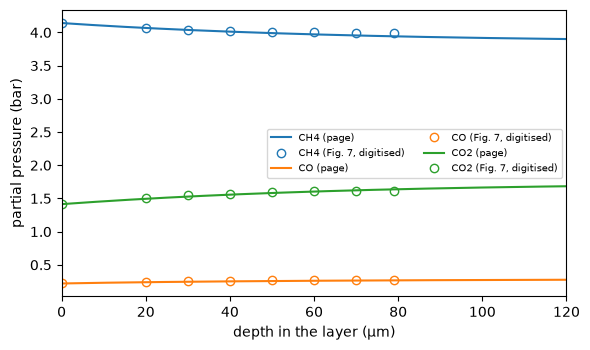

In [12]:
F6_4 = float(np.interp(4.0, F6.z_m, F6.eta1)), float(np.interp(4.0, F6.z_m, F6.eta3))
ERR7 = {m_[0]: float(m_[1]) for m_ in __import__("re").findall(
    r"(\w+) ([0-9.]+)", load_meta("xu-froment-1989-ii-fig7.csv", page=PAGE)["acquisition"]["estimated_error"].split(" bar")[0])}


def skeletal_case(case):
    """rho_s read as the skeletal density: the pellet density, which enters the source term and rho_B, is
    rho_s (1 - eps_s), with eps_s = V_g / (1/rho_s + V_g)."""
    return replace(case, eps_s=TAB["eps_s_rho_skeletal"], rho_s=case.rho_s * (1 - TAB["eps_s_rho_skeletal"]))


def fig7_state(case):
    ps = np.array([F7.loc[k, "x_0e-5m"] for k in ("CH4", "H2O", "H2", "CO", "CO2")])
    n = case.moles(FIG["F7_x_from_surface"], FIG["F7_y_from_surface"])
    pt = ps[0] * n.sum() / n[0]                      # total pressure that matches the read CH4
    return case.state(FIG["F7_x_from_surface"], FIG["F7_y_from_surface"], pt)


def r2_study(ring=None, T=None, n=160, base=None):
    """eta1, eta3 at the Fig. 7 state; the band over the choices; profiles against Fig. 7."""
    base = CASE if base is None else base
    ring = base.ring_factor if ring is None else ring
    T = FIG["F7F5_T_from_V1_K"] if T is None else T
    out, band = {}, []
    for rd in (False, True):
        for TT in (FIG["F3_T4_K"], FIG["F7F5_T_from_V1_K"]):
            for a in (1.0, 2.246):
                for cut in (None, 0.08e-3):
                    case = replace(skeletal_case(base) if rd else base, act=a)
                    pb, yf = fig7_state(case)
                    De = case.d_eff(yf, TT, sum(pb) / (1 - yf[5]))
                    e = M.pellet_rates(case, pb, TT, De, n=n // 2, cut=cut)
                    band.append((a, e[0] / case.rates(pb, TT)[0] / ring))
    for nm, a_ in (("a1", 1.0), ("fresh", 2.246)):
        b_ = [v_ for a, v_ in band if a == a_]
        out[f"R2_eta1_band_{nm}_min"], out[f"R2_eta1_band_{nm}_max"] = min(b_), max(b_)
    pb, yf = fig7_state(base)
    pt = sum(pb) / (1 - yf[5])
    De = base.d_eff(yf, T, pt)
    ext, v, sols, pels = M.pellet_rates(base, pb, T, De, n=n, levels=2, return_all=True)
    r = base.rates(pb, T)
    out["R2_eta1_4m"], out["R2_eta3_4m"] = ext[0] / r[0] / ring, ext[2] / r[2] / ring
    out["R2_eta1_minus_fig6"] = out["R2_eta1_4m"] - F6_4[0]
    out["R2_band_a1_min_minus_fig6"] = out["R2_eta1_band_a1_min"] - F6_4[0]
    out["R2_surface_H2_below_read"] = F7.loc["H2", "x_0e-5m"] - pb[2]
    out["R2_surface_H2O_below_read"] = F7.loc["H2O", "x_0e-5m"] - pb[1]
    U, pel = sols[-1], pels[-1]
    prof = dict(zip(("CH4", "H2O", "H2", "CO", "CO2"), pel.dependent(U[:, 0], U[:, 1], pb, De)))
    cols = [c for c in F7.columns if c.startswith("x_") and c != "x_0e-5m"]
    depth = [float(c[2:-1]) for c in cols]
    inside, total, worst = 0, 0, {}
    for sp in ("CH4", "H2O", "H2", "CO", "CO2"):
        d = np.interp(depth, pel.x_c, prof[sp]) - F7.loc[sp, cols].to_numpy(float)
        ok = np.isfinite(d)
        inside += int(np.sum(abs(d[ok]) <= ERR7[sp]))
        total += int(ok.sum())
        worst[sp] = float(d[ok][np.argmax(abs(d[ok]))])
    out["R2_fig7_inside"], out["R2_fig7_total"] = inside, total
    out["R2_fig7_H2_worst_bar"] = worst["H2"]
    out["R2_fig7_CH4_worst_bar"] = worst["CH4"]
    return out, prof, pel


R2, PROF, PEL7 = r2_study()
say(f"At the 4 m state ({R2['R2_eta1_4m']:.4f} for eta1 and {R2['R2_eta3_4m']:.4f} for eta3 at "
    f"{FIG['F7F5_T_from_V1_K']:.2f} K) the page lies above Fig. 6 ({F6_4[0]:.4f} ± 0.0007). At a = 1, "
    f"eta1 spans {R2['R2_eta1_band_a1_min']:.4f} to {R2['R2_eta1_band_a1_max']:.4f} over eps_s, T and the "
    f"0.08 mm cut: "
    f"{'above' if R2['R2_band_a1_min_minus_fig6'] > 0.0007 else 'not above'} Fig. 6 in every member; with "
    f"a = 2.246 it spans {R2['R2_eta1_band_fresh_min']:.4f} to {R2['R2_eta1_band_fresh_max']:.4f}, "
    f"{'which contains' if R2['R2_eta1_band_fresh_min'] <= F6_4[0] <= R2['R2_eta1_band_fresh_max'] else 'which does not contain'} "
    f"Fig. 6. Against Fig. 7's profiles (2e-5 to 7.9e-5 m) the profiles disagree: {R2['R2_fig7_inside']} of "
    f"{R2['R2_fig7_total']} points lie inside the reading error; the largest H2 difference is "
    f"{R2['R2_fig7_H2_worst_bar']:+.4f} bar and CH4 {R2['R2_fig7_CH4_worst_bar']:+.4f} bar. The page's "
    f"surface state follows the stoichiometry, so its H2 and H2O start {R2['R2_surface_H2_below_read']:.4f} "
    f"and {R2['R2_surface_H2O_below_read']:.4f} bar below Fig. 7's read surface values. "
    f"At condition C the cut at 0.08 mm keeps {PC['C_robs_CH4_cut_over_full']:.6f} of the full layer's "
    f"CH4 rate; the lateral layers as cylindrical shells give {PC['C_shell_outer_over_slab_CH4']:.5f} "
    f"(outer) and {PC['C_shell_inner_over_slab_CH4']:.6f} (inner) of the slab rate per volume, "
    f"{PC['C_lateral_ring_over_slab_CH4']:.6f} volume-weighted: the slab is right for the lateral "
    f"faces and the division by 1.071 is not supported by them. At the inlet state the observed "
    f"activation energy is {C0['C0_Eapp_observed_CH4_kJmol']:.2f} kJ/mol against "
    f"{C0['C0_Eapp_intrinsic_CH4_kJmol']:.2f} intrinsic, a ratio of {C0['C0_Eapp_ratio']:.4f}, not "
    f"\"approximately half\" (S7); eta_CH4 there is {C0['C0_eta_CH4_ring']:.5f}.")

fig, ax = plt.subplots(figsize=(6, 3.6))
xs = PEL7.x_c * 1e6
for sp, c in zip(("CH4", "CO", "CO2"), ("C0", "C1", "C2")):
    ax.plot(xs, PROF[sp], color=c, label=f"{sp} (page)")
    cols = [k for k in F7.columns if k.startswith("x_")]
    ax.plot([float(k[2:-1]) * 1e6 for k in cols], F7.loc[sp, cols], "o", color=c, mfc="none",
            label=f"{sp} (Fig. 7, digitised)")
ax.set_xlim(0, 120)
ax.set_xlabel("depth in the layer (µm)")
ax.set_ylabel("partial pressure (bar)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

### R4: the message, catalyst against heat

The base tube: Table 2's feed, Fig. 3's pressure, a flux with Fig. 3's wall-difference
shape and the duty of Fig. 3's exit state (A7). The exit-conversion elasticities at the
end of heating (11.12 m) are e_a = ln(x(2a)/x(a/2))/ln 4 and e_Q = ln(x(1.1 Q)/x(Q))/ln 1.1.
The same under an imposed external wall temperature (a straight line through Fig. 3's
T_w) with U calibrated to the same duty; there the heat step is T_w + 10 K and e_Q uses
the duties the two tubes take up. The criterion was fixed before the runs: S1 is
confirmed if e_a/e_Q ≤ 0.1 in both forms at the base and in every sweep, refuted if
above 0.3 in either base.

In [13]:
Q_BASE = FIG["F3_duty_W_axis_as_x"]
NS2 = (100, 200)
TW_Z = np.array([0.0, CASE.L_tot])


def tw_heat(U, dT=0.0):
    return ("Tw", TW_Z, np.polyval(TW_COEF, TW_Z) + dT, U)


def duty_at(res, key, ns):
    v = []
    for n in ns:
        z, Y, Qs = res[(key, n)]
        v.append(Qs[int(np.argmin(abs(z - CASE.L_heat)))])
    return 2 * v[1] - v[0] if len(v) == 2 else v[0]


def calibrate_U(dT=0.0):
    """U (W/(m2 K)) for which the imposed-T_w tube takes up Q_BASE to 11.12 m (n_z = 100)."""
    Us = np.array([300.0, 400.0, 500.0, 650.0])
    res = tubes({(f"U{U:g}", 100): (CASE, tw_heat(U, dT), FIG3_PT, 100, None, False) for U in Us})
    d = np.array([duty_at(res, f"U{U:g}", (100,)) for U in Us])
    U1 = float(CubicSpline(d, Us)(Q_BASE))
    for _ in range(3):
        U2 = 1.001 * U1
        res = tubes({(k, 100): (CASE, tw_heat(u, dT), FIG3_PT, 100, None, False)
                     for k, u in (("a", U1), ("b", U2))})
        da, db = duty_at(res, "a", (100,)), duty_at(res, "b", (100,))
        U1 = U1 + (Q_BASE - da) * (U2 - U1) / (db - da)
    return {"U_TW": U1}


U_TW = calibrate_U()["U_TW"]


def message_study(form="flux", a_base=1.0, case=None, Q=None, shape="fig3", cut=None, ns=NS2):
    """e_a, e_Q and their ratio at 11.12 m; ``ns`` two levels (Richardson) or one."""
    case = CASE if case is None else case
    Q = Q_BASE if Q is None else Q
    if form == "flux":
        h0, h1 = ("q", flux_coef(Q, shape)), ("q", flux_coef(1.1 * Q, shape))
    else:
        h0, h1 = tw_heat(U_TW), tw_heat(U_TW, 10.0)
    runs = {"half": (replace(case, act=0.5 * a_base), h0), "base": (replace(case, act=a_base), h0),
            "double": (replace(case, act=2.0 * a_base), h0), "heat": (replace(case, act=a_base), h1)}
    res = tubes({(k, n): (c, h, FIG3_PT, n, cut, False) for k, (c, h) in runs.items() for n in ns})
    X = {k: (extrap(res, k, ns, [CASE.L_heat])[0] if len(ns) == 2 else
             res[(k, ns[0])][1][int(np.argmin(abs(res[(k, ns[0])][0] - CASE.L_heat)))]) for k in runs}
    x = X["base"][0]
    e_a = math.log(X["double"][0] / X["half"][0]) / math.log(4.0)
    if form == "flux":
        e_Q = math.log(X["heat"][0] / x) / math.log(1.1)
    else:
        e_Q = math.log(X["heat"][0] / x) / math.log(duty_at(res, "heat", ns) / duty_at(res, "base", ns))
    out = {"x": x, "T": X["base"][2], "e_a": e_a, "e_Q": e_Q, "ratio": e_a / e_Q,
           "duty_kW": duty_at(res, "base", ns) / 1e3,
           "duty_double_change_pct": 100 * (duty_at(res, "double", ns) / duty_at(res, "base", ns) - 1)}
    if form == "flux":
        H0 = case.h_flow(0, 0, case.T0)
        xe = case.equilibrium_state(H0 + Q, float(np.interp(CASE.L_heat, *FIG3_PT)))[0]
        out["dx_inf"] = xe - x
        out["heat_equiv_pct"] = 100 * (math.exp(math.log(xe / x) / e_Q) - 1)
    return out, res


MSG_F, RES_F = message_study("flux")
MSG_W, RES_W = message_study("Tw")
LOW_F, _ = message_study("flux", a_base=0.01)
LOW_W, _ = message_study("Tw", a_base=0.01)
print(f"U calibrated: {U_TW:.2f} W/(m2 K); duty base flux {MSG_F['duty_kW']:.3f} kW, T_w form {MSG_W['duty_kW']:.3f} kW")
msg = pd.DataFrame({k: {"e_a": d["e_a"], "e_Q": d["e_Q"], "e_a/e_Q": d["ratio"], "x(11.12 m)": d["x"],
                        "T(11.12 m) K": d["T"], "duty kW": d["duty_kW"]}
                    for k, d in (("imposed flux, a = 1", MSG_F), ("imposed T_w, a = 1", MSG_W),
                                 ("imposed flux, a = 0.01", LOW_F), ("imposed T_w, a = 0.01", LOW_W))}).T
show(msg.rename_axis("case").reset_index(), "d31msg", "5g")

U calibrated: 367.23 W/(m2 K); duty base flux 238.024 kW, T_w form 238.392 kW


case,e_a,e_Q,e_a/e_Q,x(11.12 m),T(11.12 m) K,duty kW
"imposed flux, a = 1",0.0075944,0.92858,0.0081785,0.5595,1027.6,238.02
"imposed T_w, a = 1",0.022128,0.93275,0.023723,0.56,1028.2,238.39
"imposed flux, a = 0.01",0.1009,0.88757,0.11368,0.47695,1099.5,238.02
"imposed T_w, a = 0.01",0.16732,0.95875,0.17452,0.39794,1049.9,196.25


sweep (n_z = 100),e_a,e_Q,e_a/e_Q,x(11.12 m)
a = 0.5,0.01101,0.9284,0.01185,0.5545
a = 1.225,0.006868,0.9286,0.007396,0.5587
a = 2,0.005328,0.9287,0.005737,0.5604
a = 2.246,0.005019,0.9287,0.005404,0.5607
eps_s skeletal reading,0.01248,0.9282,0.01345,0.553
geometric pore diameters,0.007745,0.9285,0.008341,0.5578
eps_B = 0.40,0.006315,0.9286,0.0068,0.5593
eps_B = 0.60,0.009654,0.9285,0.0104,0.5558
K factors of R1,0.007954,0.9233,0.008614,0.5642
rate zero beyond 0.08 mm,0.01178,0.9296,0.01267,0.5571


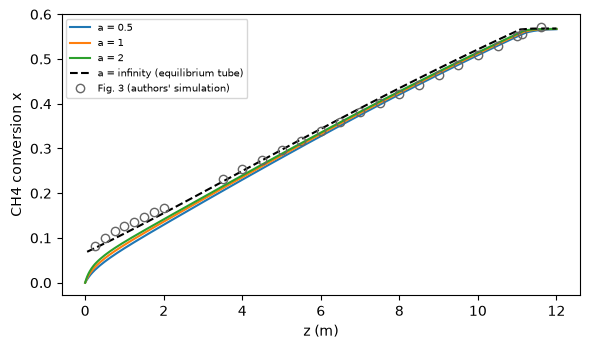

In [14]:
SWEEPS = {
    "a = 0.5": dict(case=replace(CASE, act=0.5)),
    "a = 1.225": dict(case=replace(CASE, act=1.225)),
    "a = 2": dict(case=replace(CASE, act=2.0)),
    "a = 2.246": dict(case=replace(CASE, act=2.246)),
    "eps_s skeletal reading": dict(case=skeletal_case(CASE)),
    "geometric pore diameters": dict(case=replace(CASE, pore_d=PORE_D_GEO)),
    "eps_B = 0.40": dict(case=replace(CASE, eps_B=0.40)),
    "eps_B = 0.60": dict(case=replace(CASE, eps_B=0.60)),
    "K factors of R1": dict(case=replace(CASE, kin=replace(KIN, eq=(KIN.eq[0], KIN.eq[1] + math.log(FIG["F3_K1_factor_implied_at_4m"]),
                                                                     KIN.eq[2], KIN.eq[3] + math.log(FIG["F3_K2_factor_implied_at_4m"]))))),
    "rate zero beyond 0.08 mm": dict(cut=0.08e-3),
    "constant flux": dict(shape="const"),
    "duty with the axis factor": dict(Q=FIG["F3_duty_W_axis_times_1pz"]),
}


def sweep_study(act_scale=1.0, form="flux"):
    """The message on one axial level (n_z = 100) over the robustness sweeps, in one form."""
    rows = {}
    for name, kw in SWEEPS.items():
        kw = dict(kw)
        if form == "Tw" and ("shape" in kw or "Q" in kw):      # the heat input does not enter that form
            continue
        c = kw.pop("case", CASE)
        a = c.act * act_scale
        d, _ = message_study(form, a_base=a, case=c, ns=(100,), **kw)
        rows[name] = d
    return rows


SW = sweep_study()
SW_RATIOS = np.array([d["ratio"] for d in SW.values()])
SW_TW = sweep_study(form="Tw")
SW_TW_RATIOS = np.array([d["ratio"] for d in SW_TW.values()])
BASE100, _ = message_study("flux", ns=(100,))
show(pd.DataFrame({k: {"e_a": d["e_a"], "e_Q": d["e_Q"], "e_a/e_Q": d["ratio"], "x(11.12 m)": d["x"]}
                   for k, d in SW.items()}).T.rename_axis("sweep (n_z = 100)").reset_index(), "d31sw", "4g")

fig, ax = plt.subplots(figsize=(6, 3.6))
for k, lab in (("half", "a = 0.5"), ("base", "a = 1"), ("double", "a = 2")):
    z, Y, _ = RES_F[(k, 200)]
    ax.plot(z, Y[:, 0], label=lab)
H0 = CASE.h_flow(0, 0, CASE.T0)
zq = np.linspace(0.05, CASE.L_tot, 40)
Qz = [Q_BASE * np.polyval(np.polyint(S_COEF), min(z_, CASE.L_heat)) / S_INT for z_ in zq]
xeq = [CASE.equilibrium_state(H0 + q_, float(np.interp(z_, *FIG3_PT)))[0] for z_, q_ in zip(zq, Qz)]
ax.plot(zq, xeq, "k--", label="a = infinity (equilibrium tube)")
f3x = F3.dropna(subset=["CH4_axis"])
ax.plot(f3x.z_m, f3x.CH4_axis, "o", mfc="none", color="0.4", label="Fig. 3 (authors' simulation)")
ax.set_xlabel("z (m)")
ax.set_ylabel("CH4 conversion x")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### R3: the base tube against Figs. 3, 5 and 6

Differences are counted against the reading error in two zones: z ≤ 4 m, where Fig. 3
carries the inlet enthalpy excess of R1 (the page's inlet is slower), and z > 4 m.

In [15]:
def r3_study(case=None, z_split=4.0):
    case = CASE if case is None else case
    res = tubes({("b", n): (case, ("q", flux_coef(Q_BASE)), FIG3_PT, n, None, False) for n in NS2})
    z = res[("b", 100)][0]
    Y = extrap(res, "b", NS2, z)
    sp = CubicSpline(z, Y)
    out = {}
    for col, j, err in (("CH4_axis", 0, 0.003), ("CO2_axis", 1, 0.003), ("T_K", 2, 1.5)):
        f = F3.dropna(subset=[col])
        d = sp(f.z_m.to_numpy())[:, j] - f[col].to_numpy()
        lo = f.z_m.to_numpy() <= z_split
        out[f"R3_{col}_outside_le4"] = int(np.sum(abs(d[lo]) > err))
        out[f"R3_{col}_n_le4"] = int(lo.sum())
        out[f"R3_{col}_outside_gt4"] = int(np.sum(abs(d[~lo]) > err))
        out[f"R3_{col}_n_gt4"] = int((~lo).sum())
    e = F3.set_index("z_m").loc[CASE.L_heat]
    x11, y11, T11 = sp(CASE.L_heat)
    out["R3_x_minus_fig3_1112"] = x11 - e.CH4_axis
    out["R3_T_minus_fig3_1112"] = T11 - e.T_K
    pt11 = float(np.interp(CASE.L_heat, *FIG3_PT))
    V = case.approach(case.state(x11, y11, pt11)[0], T11)
    f5 = F5.set_index("z_m").loc[11.1]
    out["R3_V1_1112"], out["R3_V2_1112"] = V[0], V[1]
    out["R3_V1_minus_fig5"] = V[0] - f5.V1

    def r2_surface(zz):
        xx, yy, TT = sp(zz)
        return case.rates(case.state(xx, yy, float(np.interp(zz, *FIG3_PT)))[0], TT)[1]
    roots = find_roots(r2_surface, 0.5, CASE.L_heat)["roots"]
    if len(roots) != 1:
        raise RuntimeError(f"expected one zero of the surface r2, found {roots}")
    out["R3_r2_zero_m"] = float(roots[0])
    return out, sp


R3, SP3 = r3_study()
say(f"At 11.12 m the base tube gives x = {SP3(CASE.L_heat)[0]:.4f} against Fig. 3's "
    f"{F3.set_index('z_m').loc[CASE.L_heat].CH4_axis:.4f} (difference {R3['R3_x_minus_fig3_1112']:+.4f}, "
    f"reading error ±0.003) and T {R3['R3_T_minus_fig3_1112']:+.1f} K from Fig. 3 (±1.5 K); "
    f"V1 = {R3['R3_V1_1112']:.4f} against Fig. 5's {F5.set_index('z_m').loc[11.1].V1:.4f}. "
    f"The duty is Fig. 3's enthalpy gain to 11.12 m (A7), so only the split between conversion and "
    f"temperature is tested there; Fig. 3's axis, labelled x/(1+ζ), is read as x. "
    f"For z > 4 m, {R3['R3_CH4_axis_outside_gt4']} of {R3['R3_CH4_axis_n_gt4']} x readings and "
    f"{R3['R3_T_K_outside_gt4']} of {R3['R3_T_K_n_gt4']} T readings lie outside the reading error; for "
    f"z ≤ 4 m, {R3['R3_CH4_axis_outside_le4']} of {R3['R3_CH4_axis_n_le4']} and "
    f"{R3['R3_T_K_outside_le4']} of {R3['R3_T_K_n_le4']}. The intrinsic r2 at the bulk (surface) "
    f"state changes sign at z = {R3['R3_r2_zero_m']:.2f} m (find_roots), against Fig. 6's dashed line "
    f"at 3.50 m, Fig. 4's zero at 3.77 m and the text's 3.4 and \"about 4\" m.")

At 11.12 m the base tube gives x = 0.5595 against Fig. 3's 0.5559 (difference +0.0036, reading error ±0.003) and T -5.4 K from Fig. 3 (±1.5 K); V1 = 0.7614 against Fig. 5's 0.7775. The duty is Fig. 3's enthalpy gain to 11.12 m (A7), so only the split between conversion and temperature is tested there; Fig. 3's axis, labelled x/(1+ζ), is read as x. For z > 4 m, 12 of 16 x readings and 13 of 15 T readings lie outside the reading error; for z ≤ 4 m, 10 of 10 and 5 of 9. The intrinsic r2 at the bulk (surface) state changes sign at z = 3.02 m (find_roots), against Fig. 6's dashed line at 3.50 m, Fig. 4's zero at 3.77 m and the text's 3.4 and "about 4" m.

## Validation

- V1: the energy budget H_flow(z) - H_flow(0) - Σ q π d_ti Δz of every tube of test case
  B, to round-off (the enthalpy-flow residual makes it exact for the march). Atoms are
  exact by the (x, y) parametrisation (structural).
- V2: the isothermal first-order slab on the page's graded grid against tanh(φ)/φ, its
  observed order, and the surface-flux rate against the volume average.
- V3: strong pore diffusion makes the observed rate scale as a^(1/2), so the deficit
  x_eq - x(a) at 11.12 m should scale as a^(-1/2).
- V4: the axial ladder n_z = 100 to 800 at first order.
- V5: the rate function against C2.1's `XuFroment.rates`.
- V6: every check value (above), from a second route.

In [16]:
def v3_study(intrinsic=False, acts=(0.5, 1.0, 2.0, 4.0, 8.0)):
    res = tubes({(f"a{a:g}", n): (replace(CASE, act=a), HB, L_PT, n, None, intrinsic)
                 for a in acts for n in NS2})
    H0 = CASE.h_flow(0, 0, CASE.T0)
    xe = CASE.equilibrium_state(H0 + 70.0e3 * math.pi * CASE.d_ti * CASE.L_heat,
                                29.0 - 0.27 * CASE.L_heat)[0]
    d = np.array([xe - extrap(res, f"a{a:g}", NS2, [CASE.L_heat])[0][0] for a in acts])
    o = np.log2(d[1:] / d[:-1])
    return {"V3_order_min": float(o.min()), "V3_order_max": float(o.max())}


V3 = v3_study()
print(f"V3 deficit orders over a = 0.5 ... 8: {V3['V3_order_min']:.4f} to {V3['V3_order_max']:.4f}; "
      f"V2 slab orders {TH['thiele_order_phi10']:.4f} and {TH['thiele_order_phi100']:.4f}; "
      f"tanh gaps below 1e-8 and 1e-7 (here {TH['thiele_eta_phi10_gap']:.0e}, {TH['thiele_eta_phi100_gap']:.0e})")


def v1_study(exact_integral=False):
    """V1: energy budget of every tube of case B and of the base message tubes."""
    H0 = CASE.h_flow(0, 0, CASE.T0)
    worst = 0.0
    for key, (z, Y, Qs) in list(B_RES.items()) + list(RES_F.items()):
        Q = Qs[-1]
        if exact_integral and key in RES_F:      # the exact integral of q, not the march's own sum
            Q = Q_BASE
        worst = max(worst, abs(CASE.h_flow(*Y[-1]) - H0 - Q) / Q)
    return {"V1_energy_invariant": worst}


V1 = v1_study()
print(f"V1: worst relative energy budget over {len(B_RES) + len(RES_F)} tubes below 1e-12 "
      f"(here {V1['V1_energy_invariant']:.0e})")


def r4_claims(form, a_base=1.0):
    d = message_study(form, a_base=a_base)[0]
    keys = ["e_a", "e_Q", "ratio", "dx_inf", "heat_equiv_pct", "duty_double_change_pct"]
    out = {f"R4_{form}_{k}": d[k] for k in keys if k in d}
    if form == "flux":                 # grid error of the one-level (n_z = 100) sweeps, relative
        d1 = message_study(form, a_base=a_base, ns=(100,))[0]
        out["R4_flux_ratio_n100_gap"] = abs(d1["ratio"] / d["ratio"] - 1)
    return out


def low_claims(a_low=0.01):
    lf, lw = message_study("flux", a_base=a_low)[0], message_study("Tw", a_base=a_low)[0]
    return {"R4_flux_low_ratio": lf["ratio"], "R4_Tw_low_ratio": lw["ratio"], "R4_flux_low_T": lf["T"],
            "R4_Tw_low_duty_change_pct": 100 * (lw["duty_kW"] / MSG_W["duty_kW"] - 1)}


def sweep_claims(act_scale=1.0):
    out = {}
    for form, key in (("flux", "R4_sweep"), ("Tw", "R4_Tw_sweep")):
        r = np.array([d["ratio"] for d in sweep_study(act_scale, form).values()])
        out[f"{key}_n_below"], out[f"{key}_max_ratio"] = int(np.sum(r < 0.1)), float(r.max())
    return out


R4 = {**r4_claims("flux"), **r4_claims("Tw"), **low_claims(), **sweep_claims()}

V3 deficit orders over a = 0.5 ... 8: -0.5052 to -0.5017; V2 slab orders 1.9998 and 1.9982; tanh gaps below 1e-8 and 1e-7 (here 2e-10, 6e-09)
V1: worst relative energy budget over 20 tubes below 1e-12 (here 3e-14)


### Claims and the break table

Every number above is registered here. Each break row injects one defect through a
study's argument, reruns the studies that defect enters and records every claim those
studies return; a claim must be failed by at least one row.

In [17]:
ALL = {**TAB, **FIG, **PC, **C0, **TH, **B, **V1, **V3, **V4, **V5, **R2, **R3, **R4, "U_TW": U_TW}
TIGHT = 1e-9       # algebra on printed numbers and digitised cells
PELLET = 1e-6      # Richardson values of pellet solves (newton tol 1e-12 on bar)
TUBE = 1e-5        # Richardson values of the march
DIFF = 1e-3        # elasticities and differences of nearby tubes
for n_ in ("T2_comp_sum_pct", "ng_hydrocarbon_carbon_kmol_h", "steam_ratio_from_Nm3", "co2_ratio_from_Nm3", "n2_ratio_from_Nm3",
           "eps_s_rho_pellet", "eps_s_rho_skeletal", "skeletal_density_if_pellet",
           "ring_av_ratio_lateral_ends", "catalyst_heated_kg", "F7_x_from_surface", "F7_y_from_surface",
           "F7_H2_over_CH4_predicted", "F7_H2_over_CH4_read", "F7_H2_over_CH4_predicted_Nm3_CO2",
           "F7_H2O_over_CH4_predicted", "F7_H2O_over_CH4_read", "F7F5_T_from_V1_K", "F7F5_T_from_V2_K",
           "F3_K1_factor_implied_at_4m", "F3_K2_factor_implied_at_4m", "F3_T4_K",
           "F3_K1_factor_fig3comp_4m", "F3_K2_factor_fig3comp_4m", "F3_K1_factor_fig3comp_1112m",
           "F3_K2_factor_fig3comp_1112m", "F3_duty_W_axis_as_x",
           "F3_duty_W_axis_times_1pz", "F3_excess_kW_0.25", "F3_excess_kW_0.75", "F3_excess_kW_6",
           "F3_lambda_st_implied"):
    claims.value(n_, ALL[n_], rtol=TIGHT)
claims.bound("ring_av_lateral_identity_gap", abs(TAB["ring_av_ratio_lateral_only"] - 1), max=1e-12,
             basis="identity", structural=True, note="the l^2 terms cancel: a_v(ring, lateral) = a_v(slab)")
for n_ in ("C_robs_CH4_cut_over_full", "C_shell_outer_over_slab_CH4", "C_shell_inner_over_slab_CH4",
           "C_lateral_ring_over_slab_CH4", "C0_Eapp_observed_CH4_kJmol", "C0_Eapp_intrinsic_CH4_kJmol",
           "C0_Eapp_ratio", "C0_eta_CH4_ring", "R2_eta1_4m", "R2_eta3_4m", "R2_eta1_band_a1_min",
           "R2_eta1_band_a1_max", "R2_eta1_band_fresh_min", "R2_eta1_band_fresh_max",
           "R2_band_a1_min_minus_fig6", "R2_surface_H2_below_read", "R2_surface_H2O_below_read"):
    claims.value(n_, ALL[n_], rtol=PELLET)
for n_ in ("R2_fig7_H2_worst_bar", "R2_fig7_CH4_worst_bar"):
    claims.value(n_, ALL[n_], rtol=1e-4)
claims.exact("R2_fig7_inside", R2["R2_fig7_inside"])
claims.exact("R2_fig7_total", R2["R2_fig7_total"], structural=True, note="digitised points, a data count")
for n_ in ("R3_x_minus_fig3_1112", "R3_T_minus_fig3_1112", "R3_V1_1112", "R3_V1_minus_fig5", "R3_r2_zero_m"):
    claims.value(n_, ALL[n_], rtol=1e-4)
for c_ in ("CH4_axis", "T_K"):
    for zone in ("le4", "gt4"):
        claims.exact(f"R3_{c_}_outside_{zone}", R3[f"R3_{c_}_outside_{zone}"])
        claims.exact(f"R3_{c_}_n_{zone}", R3[f"R3_{c_}_n_{zone}"], structural=True, note="digitised points")
for n_ in ("R4_flux_e_a", "R4_flux_e_Q", "R4_flux_ratio", "R4_flux_dx_inf", "R4_flux_heat_equiv_pct",
           "R4_Tw_e_a", "R4_Tw_e_Q", "R4_Tw_ratio", "R4_Tw_duty_double_change_pct", "R4_flux_low_ratio",
           "R4_Tw_low_ratio", "R4_Tw_low_duty_change_pct", "R4_sweep_max_ratio", "R4_Tw_sweep_max_ratio", "R4_flux_ratio_n100_gap"):
    claims.value(n_, ALL[n_], rtol=DIFF)
claims.value("R4_flux_low_T", ALL["R4_flux_low_T"], rtol=TUBE)
claims.value("U_TW", U_TW, rtol=1e-6, unit="W/(m2 K)")
claims.count("R4_sweep_n_below", SW_RATIOS, 0.1, min_margin=0.1, above=False)
claims.count("R4_Tw_sweep_n_below", SW_TW_RATIOS, 0.1, min_margin=0.1, above=False)
claims.bound("V1_energy_invariant", V1["V1_energy_invariant"], max=1e-12, basis="identity")
claims.bound("thiele_eta_phi10_gap", TH["thiele_eta_phi10_gap"], max=1e-8, basis="theory")
claims.bound("thiele_eta_phi100_gap", TH["thiele_eta_phi100_gap"], max=1e-7, basis="theory")
claims.bound("thiele_order_phi10", TH["thiele_order_phi10"], min=1.9, max=2.1, basis="theory")
claims.bound("thiele_order_phi100", TH["thiele_order_phi100"], min=1.9, max=2.1, basis="theory")
claims.bound("V3_order_min", V3["V3_order_min"], min=-0.55, max=-0.45, basis="theory")
claims.bound("V3_order_max", V3["V3_order_max"], min=-0.55, max=-0.45, basis="theory")
claims.bound("V4_order_min", V4["V4_order_min"], min=0.9, max=1.1, basis="theory")
claims.bound("V4_order_max", V4["V4_order_max"], min=0.9, max=1.1, basis="theory")
claims.bound("V4_T1112_order_finest", V4["V4_T1112_order_finest"], min=0.9, max=1.3, basis="chosen",
             note="T at 11.12 m has a first-order error below 1e-3 K; its order approaches 1 from above")
claims.bound("V5_rate_gap", V5["V5_rate_gap"], max=1e-13, basis="identity")

ROWS = [
    ("normal volume at 20 °C (24.055 m3/kmol)", [(table2_study, dict(molar_volume=24.055))]),
    ("CH4 entry of Table 2 read as 81.4", [(table2_study, dict(y_ch4_pct=81.4))]),
    ("steam/CH4 of 3.0 in the pellet state", [(r2_study, dict(base=replace(CASE, n0=np.array([1.0, 3.0, 0.122, 0.0, 0.056, 0.164]))))]),
    ("H2 in the feed 0.3 per CH4 in the pellet state", [(r2_study, dict(base=replace(CASE, n0=np.array([1.0, 3.358, 0.3, 0.0, 0.056, 0.164]))))]),
    ("rho_s read as skeletal density", [(table2_study, dict(rho_skeletal=True))]),
    ("first pore class of Table 1 dropped", [(table2_study, dict(drop_first_pore=True))]),
    ("active layer 3 mm", [(table2_study, dict(l_act=0.003))]),
    ("eps_B = 0.40", [(table2_study, dict(eps_B=0.40)), (r3_study, dict(case=replace(CASE, eps_B=0.40)))]),
    ("CO2/CH4 from the Nm3 feed", [(figure_study, dict(co2_nm3=True))]),
    ("Fig. 7 surface read at the 2e-5 m column", [(figure_study, dict(col="x_2e-5m"))]),
    ("T(4 m) read on the inner-skin curve", [(figure_study, dict(t_col="T_i_K"))]),
    ("Fig. 5 read at 5 m for 4 m", [(figure_study, dict(f5_z=5.0))]),
    ("Fig. 5 read at 10 m for 11.1 m", [(figure_study, dict(f5_end=10.0))]),
    ("enthalpy without formation (reaction heat dropped)", [(figure_study, dict(sensible=True))]),
    ("ring factor omitted", [(pellet_c_study, dict(ring=1.0)), (c0_study, dict(ring=1.0)),
                             (r2_study, dict(ring=1.0))]),
    ("Knudsen diffusion off", [(pellet_c_study, dict(case=replace(CASE, knudsen=False))),
                               (r2_study, dict(base=replace(CASE, knudsen=False)))]),
    ("cut at 0.8 mm", [(pellet_c_study, dict(cut=0.8e-3))]),
    ("outer layer radius taken as d_pe", [(pellet_c_study, dict(outer_radius=P("d_pe")))]),
    ("inner layer radius taken as d_pi", [(pellet_c_study, dict(inner_radius=P("d_pi")))]),
    ("D_e frozen at 793.15 K", [(c0_study, dict(freeze_De=True))]),
    ("pellet at Fig. 3's T(4 m)", [(r2_study, dict(T=FIG["F3_T4_K"]))]),
    ("activity 1.225 in the base tube", [(r3_study, dict(case=replace(CASE, act=1.225)))]),
    ("T_w line 10 K higher in the calibration", [(calibrate_U, dict(dT=10.0))]),
    ("message at a = 0.01", [(r4_claims, dict(form="flux", a_base=0.01)),
                             (r4_claims, dict(form="Tw", a_base=0.01))]),
    ("low-activity case at a = 0.1", [(low_claims, dict(a_low=0.1))]),
    ("activity times 0.01 in every sweep", [(sweep_claims, dict(act_scale=0.01))]),
    ("eta forced to 1 (intrinsic rates, no pellet)", [(v3_study, dict(intrinsic=True))]),
    ("axial ladder with one level unscaled (300 for 400)", [(v4_study, dict(actual={400: 300}))]),
    ("slab ladder with one level unscaled (480 for 640)", [(thiele_study, dict(actual={640: 480}))]),
    ("K_H2O at T_ref 648 K", [(v5_study, dict(K_H2O_T=648.0)),
                              (c0_study, dict(case=replace(CASE, K_H2O_T=648.0)))]),
    ("zones split at 2 m instead of 4 m", [(r3_study, dict(z_split=2.0))]),
    ("heat by the exact integral, not the march's sum", [(v1_study, dict(exact_integral=True))]),
]
claims.define_rows([label for label, _ in ROWS])
BREAK, CRASH = [], []
for label, runs in ROWS:
    got = {}
    for fn, kw in runs:
        try:
            with np.errstate(all="ignore"):
                r = fn(**kw)
        except (RuntimeError, ValueError, FloatingPointError, AssertionError) as e:
            CRASH.append(f"{label}: {fn.__name__}: {type(e).__name__}: {str(e)[:120]}")
            continue
        got.update(r[0] if isinstance(r, tuple) else r)
    for name, x in got.items():
        if name in claims.metrics and not claims.metrics[name].get("structural"):
            if isinstance(x, (float, np.floating)) and not np.isfinite(x):
                continue
            BREAK.append((label, name, claims.breaks(label, name, x)))
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
show(pd.DataFrame([(r_, sum(cs), len(cs)) for r_, cs in by_row.items()],
                  columns=["injected defect", "claims failed", "claims recorded"]), "d31bt")
caught = {m_ for r_, m_, c_ in BREAK if c_}
open_ = sorted(k_ for k_ in claims.metrics if k_ not in caught and not claims.metrics[k_].get("structural"))
print(f"rows that crashed: {'; '.join(CRASH) or 'none'}")
print(f"{len(ROWS)} rows; {len(caught)} of {len(claims.metrics)} claims are failed by at least one row; "
      f"open: {', '.join(open_) or 'none'}")

injected defect,claims failed,claims recorded
normal volume at 20 °C (24.055 m3/kmol),4,10
CH4 entry of Table 2 read as 81.4,2,10
steam/CH4 of 3.0 in the pellet state,11,12
H2 in the feed 0.3 per CH4 in the pellet state,10,12
rho_s read as skeletal density,2,10
first pore class of Table 1 dropped,3,10
active layer 3 mm,1,10
eps_B = 0.40,9,19
CO2/CH4 from the Nm3 feed,4,22
Fig. 7 surface read at the 2e-5 m column,11,22


rows that crashed: none
32 rows; 91 of 97 claims are failed by at least one row; open: none


### The finding

In [18]:
n_sw, n_tw = len(SW_RATIOS), len(SW_TW_RATIOS)
R4_max = max(R4["R4_flux_ratio"], R4["R4_Tw_ratio"], R4["R4_sweep_max_ratio"], R4["R4_Tw_sweep_max_ratio"])
verdict = ("confirmed" if R4_max <= 0.1
           else "refuted" if max(R4["R4_flux_ratio"], R4["R4_Tw_ratio"]) > 0.3 else "partly confirmed")
say(f"**Inside this page's rebuild of the paper's model (page choices A1 to A10: the activity, the "
    f"equilibrium constants and U are not the authors'), S1 is {verdict} by the criterion fixed before the "
    f"runs.** At the base (Fig. 3's duty "
    f"{Q_BASE / 1e3:.3f} kW, a = 1) under imposed flux, e_a = {R4['R4_flux_e_a']:.5f} and "
    f"e_Q = {R4['R4_flux_e_Q']:.4f}: ratio {R4['R4_flux_ratio']:.4f}. Under an imposed wall "
    f"temperature (U = {U_TW:.1f} W/(m² K)), e_a = {R4['R4_Tw_e_a']:.5f}, e_Q = {R4['R4_Tw_e_Q']:.4f}, "
    f"ratio {R4['R4_Tw_ratio']:.4f}; doubling the activity there raises the duty by "
    f"{R4['R4_Tw_duty_double_change_pct']:.2f} %. The tube values are Richardson-extrapolated from "
    f"n_z = 100 and 200; the one-level (n_z = 100) ratio differs from the extrapolated one by "
    f"{100 * R4['R4_flux_ratio_n100_gap']:.2f} % (relative), the grid error of the sweeps. An infinitely active "
    f"catalyst adds {R4['R4_flux_dx_inf']:.4f} to x(11.12 m), worth {R4['R4_flux_heat_equiv_pct']:.2f} % "
    f"more heat. Over the robustness sweeps (n_z = 100) {R4['R4_sweep_n_below']} of {n_sw} ratios are below "
    f"0.1 under imposed flux (largest {R4['R4_sweep_max_ratio']:.4f}) and {R4['R4_Tw_sweep_n_below']} of "
    f"{n_tw} under imposed wall temperature (largest {R4['R4_Tw_sweep_max_ratio']:.4f}, the rate cut at "
    f"0.08 mm).\n\n"
    f"Why the wall-temperature form is the discriminating one: under a fixed flux, energy forces the "
    f"conversion. At a = 0.01 both forms exceed the 0.1 criterion: {R4['R4_flux_low_ratio']:.3f} under "
    f"imposed flux (gas at {R4['R4_flux_low_T']:.0f} K, the hottest tube this page solves; the H2 Shomate "
    f"row is valid to 1000 K) and {R4['R4_Tw_low_ratio']:.3f} under fixed T_w, where the duty changes by "
    f"{R4['R4_Tw_low_duty_change_pct']:.1f} %. The confirmation therefore holds for the swept activities "
    f"(0.5 to 2.246), not for a catalyst a hundred times less active. "
    f"The pellet at the 4 m state gives eta1 = {R2['R2_eta1_4m']:.4f} against Fig. 6's "
    f"{F6_4[0]:.4f} ± 0.0007; the bands of R2 are {R2['R2_eta1_band_a1_min']:.4f} to "
    f"{R2['R2_eta1_band_a1_max']:.4f} at a = 1 and {R2['R2_eta1_band_fresh_min']:.4f} to "
    f"{R2['R2_eta1_band_fresh_max']:.4f} at a = 2.246. The comparison throughout is with the authors' "
    f"simulation, not with plant data, and it holds for this furnace and the swept heat range only.")

**Inside this page's rebuild of the paper's model (page choices A1 to A10: the activity, the equilibrium constants and U are not the authors'), S1 is confirmed by the criterion fixed before the runs.** At the base (Fig. 3's duty 238.024 kW, a = 1) under imposed flux, e_a = 0.00759 and e_Q = 0.9286: ratio 0.0082. Under an imposed wall temperature (U = 367.2 W/(m² K)), e_a = 0.02213, e_Q = 0.9327, ratio 0.0237; doubling the activity there raises the duty by 0.90 %. The tube values are Richardson-extrapolated from n_z = 100 and 200; the one-level (n_z = 100) ratio differs from the extrapolated one by 0.53 % (relative), the grid error of the sweeps. An infinitely active catalyst adds 0.0082 to x(11.12 m), worth 1.58 % more heat. Over the robustness sweeps (n_z = 100) 12 of 12 ratios are below 0.1 under imposed flux (largest 0.0134) and 10 of 10 under imposed wall temperature (largest 0.0383, the rate cut at 0.08 mm).

Why the wall-temperature form is the discriminating one: under a fixed flux, energy forces the conversion. At a = 0.01 both forms exceed the 0.1 criterion: 0.114 under imposed flux (gas at 1100 K, the hottest tube this page solves; the H2 Shomate row is valid to 1000 K) and 0.175 under fixed T_w, where the duty changes by -17.7 %. The confirmation therefore holds for the swept activities (0.5 to 2.246), not for a catalyst a hundred times less active. The pellet at the 4 m state gives eta1 = 0.0315 against Fig. 6's 0.0196 ± 0.0007; the bands of R2 are 0.0259 to 0.0352 at a = 1 and 0.0198 to 0.0235 at a = 2.246. The comparison throughout is with the authors' simulation, not with plant data, and it holds for this furnace and the swept heat range only.

## What pymrm adds

Plain reuse, not an extension. The plug-flow tube is an initial-value problem with a
stiff inlet layer, so it is marched in z; each implicit-Euler step is a nested solve: an
outer `newton` on (x, y, T) whose residual calls an inner `newton` on the slab
(`construct_grad`/`construct_div` on a grid graded to the surface, `NumJac` for the
pointwise source), warm-started from the last converged step. `compute_boundary_values` gives
the surface flux and the inner-face plateau, `find_roots` the sign change of r2 and
`observed_orders` the ladders. The same numbers come from an independent scipy route
(Radau with a finite-difference slab): every check row agrees to its tolerance.

## Reuse

`model.py` takes any kinetics object with C2.1's `constants` and `equilibrium`
methods: `Pellet` for a slab or a cylindrical shell of one active layer, `Tube` for an
imposed flux or wall temperature, `run_tube` for a process pool. Before reusing the
numbers: the activity level and the equilibrium constants of Part II are not printed
(A1, A2), Table 2's feed does not close (R1), and Fig. 3's inlet holds more enthalpy than
its heat input explains (R1); the elasticities hold for this tube, this furnace shape and
the swept heat range.

In [19]:
POOL.shutdown()
claims.report();

Claims for D3.1:
  T2_comp_sum_pct                  = 100.1            value  rtol 1e-09
  ng_hydrocarbon_carbon_kmol_h     = 5.4027           value  rtol 1e-09
  steam_ratio_from_Nm3             = 3.446            value  rtol 1e-09
  co2_ratio_from_Nm3               = 0.011654         value  rtol 1e-09
  n2_ratio_from_Nm3                = 0.16433          value  rtol 1e-09
  eps_s_rho_pellet                 = 0.59068          value  rtol 1e-09
  eps_s_rho_skeletal               = 0.37134          value  rtol 1e-09
  skeletal_density_if_pellet       = 5754             value  rtol 1e-09
  ring_av_ratio_lateral_ends       = 1.3828           value  rtol 1e-09
  catalyst_heated_kg               = 106.16           value  rtol 1e-09
  F7_x_from_surface                = 0.24263          value  rtol 1e-09
  F7_y_from_surface                = 0.20255          value  rtol 1e-09
  F7_H2_over_CH4_predicted         = 1.3896           value  rtol 1e-09
  F7_H2_over_CH4_read              = 1.3976    